
# Aircraft Landing Time Prediction

Our goal is to build a neural network using PyTorch that predicts how many seconds remain until an aircraft crosses the landing threshold of runway 18R at Amsterdam Schiphol Airport.

We use a snapshot taken when the aircraft is first confirmed to be aligned with the runway.

## 1. Import Libraries

We begin by importing the Python libraries needed for our machine learning project.

- **PyTorch (`torch`)** — Building and training our neural network.
- **Pandas (`pandas`)** — Loading and manipulating our dataset.
- **NumPy (`numpy`)** — Working with numerical data.
- **Matplotlib (`matplotlib`)** — Visualizing our results.
- **Scikit-learn (`sklearn`)** — Splitting our dataset and scaling input features.

We will first verify that PyTorch is installed and functioning correctly.


In [2]:

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Verify that PyTorch is working
print("PyTorch version:", torch.__version__)
print("PyTorch working:", torch.tensor([1.0, 2.0, 3.0]))


PyTorch version: 2.8.0+cpu
PyTorch working: tensor([1., 2., 3.])



## 2. Load and Inspect the Dataset

We will load our `training.csv` file using Pandas.

Each row represents one aircraft approach, recorded at the moment the aircraft was first confirmed to be aligned with runway 18R.

Our dataset contains:
- **194 rows** representing aircraft approaches.
- **11 input features** describing the aircraft's position, movement, and estimated arrival time.
- **1 target value** (`remaining_time_s`) representing the actual remaining seconds until the aircraft crosses the runway threshold.
- **6 metadata columns** containing identifiers and other information that will not be used as neural network inputs.

We will display the first row to understand how our data is structured.


In [3]:

from pathlib import Path

# Locate the original 194-row dataset from this notebook or the repository.
data_dir = next(
    (base / "training" / "194_airplanes"
     for base in (Path.cwd(), *Path.cwd().parents)
     if (base / "training" / "194_airplanes" / "training.csv").is_file()),
    Path.cwd(),
)
csv_path = data_dir / "training.csv"

# Load the dataset into a Pandas DataFrame
df = pd.read_csv(csv_path)

# Display dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

# Display all columns of the first row
pd.set_option("display.max_columns", None)
display(df.head(1))


Rows: 194
Columns: 18


,example_id,flight_id,icao24,callsign,runway,snapshot_time_utc,latitude_deg,longitude_deg,baro_altitude_m,groundspeed_mps,track_deg,vertical_rate_mps,distance_to_threshold_m,cross_track_m,track_error_deg,speed_toward_threshold_mps,baseline_eta_s,remaining_time_s
0,EHAM18R_485122_20230315T002114,485122_20230315T002114,485122,TRA64V,18R,2023-03-15T00:34:04+00:00,52.480293,4.722552,739.14,110.091111,182.675427,-6.17728,13377.162863,11.183925,-0.524573,110.086497,121.51502,151.700454



## 3. Select Input Features and Target

Our dataset contains 18 columns, but not every column should be used to train the neural network.

We will use `schema.json` to identify which columns belong to our model.

### Input features (X)

The model will receive 11 numerical features describing the aircraft's current state.

These include its position, altitude, speed, direction, distance to the runway threshold, and baseline estimated arrival time.

### Target (y)

Our target is `remaining_time_s`.

This is the actual estimated number of seconds between the alignment snapshot and crossing the runway threshold.

During training, the neural network will learn to map the input features (X) to the target value (y).

We will exclude identifying metadata such as flight IDs, callsigns, and timestamps.

For now, we will only display the selected columns. We are not modifying our original dataset.


In [4]:

import json

# Locate our schema file
schema_path = csv_path.with_name("schema.json")

# Read the schema
with open(schema_path, "r", encoding="utf-8") as f:
    schema = json.load(f)

# Get the input and target column names
input_columns = schema["feature_columns"]
target_column = schema["target_column"]

# Create a view containing only model inputs and target
model_df = df[input_columns + [target_column]].copy()

print("Input features:", len(input_columns))
print("Target:", target_column)
print("Shape:", model_df.shape)

# Display one row
display(model_df.head(1))


Input features: 11
Target: remaining_time_s
Shape: (194, 12)


,latitude_deg,longitude_deg,baro_altitude_m,groundspeed_mps,track_deg,vertical_rate_mps,distance_to_threshold_m,cross_track_m,track_error_deg,speed_toward_threshold_mps,baseline_eta_s,remaining_time_s
0,52.480293,4.722552,739.14,110.091111,182.675427,-6.17728,13377.162863,11.183925,-0.524573,110.086497,121.51502,151.700454



## 4. Check Data Quality

Before training our neural network, we need to verify that our input features and target values are valid.

We will check:

1. **Missing values (NaN):** Missing data can cause problems during training.
2. **Infinite values:** Neural networks cannot train normally using infinite numbers.
3. **Minimum and maximum values:** These help us understand the ranges of our features.
4. **Physically invalid values:** Remaining time, distance to the runway, and forward speed should be positive in our accepted approach snapshots.

An important observation is that our features use different units and scales. For example, altitude is measured in meters, while latitude is measured in degrees.

We will later use feature scaling to help the neural network learn effectively.

For now, we are only inspecting the data. We will not remove or modify any rows.


In [5]:

# Create a data quality report
quality_report = pd.DataFrame({
    "Data type": model_df.dtypes,
    "Missing": model_df.isna().sum(),
    "Infinite": model_df.apply(lambda col: np.isinf(col).sum()),
    "Minimum": model_df.min(),
    "Maximum": model_df.max()
})

display(quality_report)

# Check for invalid values
print("Rows with missing or infinite values:",
      (~np.isfinite(model_df.to_numpy())).any(axis=1).sum())

print("Non-positive remaining time:",
      (model_df["remaining_time_s"] <= 0).sum())

print("Non-positive distance to threshold:",
      (model_df["distance_to_threshold_m"] <= 0).sum())

print("Non-positive speed toward threshold:",
      (model_df["speed_toward_threshold_mps"] <= 0).sum())


,Data type,Missing,Infinite,Minimum,Maximum
latitude_deg,float64,0,0,52.405243,52.576423
longitude_deg,float64,0,0,4.715729,4.730948
baro_altitude_m,float64,0,0,243.840000,1379.220000
groundspeed_mps,float64,0,0,62.762222,111.120000
track_deg,float64,0,0,178.295272,188.546960
vertical_rate_mps,float64,0,0,-8.778240,2.275840
distance_to_threshold_m,float64,0,0,5013.054801,24089.374834
cross_track_m,float64,0,0,-93.472713,82.336266
track_error_deg,float64,0,0,-4.904728,5.346960
speed_toward_threshold_mps,float64,0,0,62.633540,111.062066


Rows with missing or infinite values: 0
Non-positive remaining time: 0
Non-positive distance to threshold: 0
Non-positive speed toward threshold: 0



## 5. Split the Dataset

We will randomly divide our dataset into three partitions:

- **70% Training:** Used to train the neural network and update its weights.
- **15% Validation:** Used to evaluate performance during model development and detect overfitting.
- **15% Testing:** Used only for final evaluation after model selection.

### Group-aware random splitting

We will use `GroupShuffleSplit` from scikit-learn.

Unlike an ordinary random row split, this method makes sure that all rows belonging to the same flight stay in the same partition.

Although our current dataset contains one row per flight, this approach also protects us if we later introduce multiple snapshots from the same flight.

We use `random_state=42` so the random split is reproducible.

We will keep all original columns, including metadata, in our split DataFrames. We will select only the approved input features when preparing data for the neural network.

Importantly, we must split the data before fitting any normalization or scaling transformations.


In [6]:

from sklearn.model_selection import GroupShuffleSplit

# First split: 70% training, 30% temporary
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.30,
    random_state=42
)

train_idx, temp_idx = next(
    splitter.split(df, groups=df["flight_id"])
)

train_df = df.iloc[train_idx].copy()
temp_df = df.iloc[temp_idx].copy()

# Second split: divide temporary data into
# 15% validation and 15% testing
splitter_2 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.50,
    random_state=42
)

val_idx, test_idx = next(
    splitter_2.split(temp_df, groups=temp_df["flight_id"])
)

val_df = temp_df.iloc[val_idx].copy()
test_df = temp_df.iloc[test_idx].copy()

# Display results
print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))
print("Testing rows:", len(test_df))

print("Total rows:",
      len(train_df) + len(val_df) + len(test_df))

# Verify no flights appear in multiple partitions
train_flights = set(train_df["flight_id"])
val_flights = set(val_df["flight_id"])
test_flights = set(test_df["flight_id"])

assert train_flights.isdisjoint(val_flights)
assert train_flights.isdisjoint(test_flights)
assert val_flights.isdisjoint(test_flights)

print("Flight overlap: None")


Training rows: 135
Validation rows: 29
Testing rows: 30
Total rows: 194
Flight overlap: None



## 6. Prepare Inputs and Normalize Features

We will separate the input features (X) from the target (y) for each dataset.

- **X:** The 11 numerical features describing the aircraft snapshot.
- **y:** The actual remaining time until the runway threshold, measured in seconds.

### Feature Standardization

We will use `StandardScaler` to standardize our input features.

The standardization formula is:

z = (x - mean) / standard_deviation

For each feature, the scaler learns its mean and standard deviation from the training set.

We will:

1. Fit the scaler using only the training inputs.
2. Transform the training inputs.
3. Transform the validation and test inputs using the same fitted scaler.

This prevents data leakage from the validation and test datasets.

### Target Values

We will leave our target values (`remaining_time_s`) unchanged.

This means our neural network will learn to predict remaining time directly in seconds.

We will convert these arrays into PyTorch tensors in the next step.


In [7]:

# Separate inputs (X) and targets (y)
X_train = train_df[input_columns].copy()
X_val = val_df[input_columns].copy()
X_test = test_df[input_columns].copy()

y_train = train_df[target_column].copy()
y_val = val_df[target_column].copy()
y_test = test_df[target_column].copy()

# Create our scaler
scaler = StandardScaler()

# Fit ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to validation and test
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# Verify dimensions
print("Training X:", X_train_scaled.shape)
print("Training y:", y_train.shape)

print("Validation X:", X_val_scaled.shape)
print("Validation y:", y_val.shape)

print("Testing X:", X_test_scaled.shape)
print("Testing y:", y_test.shape)

# Display one original row
print("\nOriginal training row:")
display(X_train.head(1))

# Display the same row after scaling
print("Standardized training row:")
display(pd.DataFrame(
    X_train_scaled,
    columns=input_columns
).head(1))

# Target remains in seconds
print("Target (seconds):", y_train.iloc[0])


Training X: (135, 11)
Training y: (135,)
Validation X: (29, 11)
Validation y: (29,)
Testing X: (30, 11)
Testing y: (30,)

Original training row:


,latitude_deg,longitude_deg,baro_altitude_m,groundspeed_mps,track_deg,vertical_rate_mps,distance_to_threshold_m,cross_track_m,track_error_deg,speed_toward_threshold_mps,baseline_eta_s
3,52.474753,4.723101,662.94,100.831111,184.98242,-3.90144,12763.780049,-60.585887,1.78242,100.782324,126.64701


Standardized training row:


,latitude_deg,longitude_deg,baro_altitude_m,groundspeed_mps,track_deg,vertical_rate_mps,distance_to_threshold_m,cross_track_m,track_error_deg,speed_toward_threshold_mps,baseline_eta_s
0,-0.566139,-0.307446,0.032865,1.39629,0.78385,-0.791864,-0.565352,-1.430742,0.78385,1.399909,-1.018897


Target (seconds): 168.975495



## 7. Convert Data to PyTorch Tensors

PyTorch uses tensors to store and process numerical data.

A tensor is similar to a NumPy array, but it supports automatic differentiation and GPU acceleration.

We will convert our training, validation, and test datasets into PyTorch tensors.

### Input Tensors (X)

Each row represents one aircraft snapshot containing 11 numerical input features.

Our training input tensor will have the shape:

(135, 11)

### Target Tensors (y)

Each target contains the actual remaining time in seconds.

We will reshape our target values into two-dimensional tensors with one output value per aircraft.

Our training target tensor will have the shape:

(135, 1)

### Data Type

We will use `torch.float32` for both inputs and targets.

This is a commonly used numerical format for training neural networks.

We will keep our tensors on the CPU for now. We can investigate GPU acceleration later.


In [8]:

# Convert input features to PyTorch tensors
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)

# Convert target values to PyTorch tensors
# Reshape targets into (number_of_rows, 1)
y_train_tensor = torch.tensor(
    y_train.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

y_val_tensor = torch.tensor(
    y_val.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

y_test_tensor = torch.tensor(
    y_test.to_numpy(), dtype=torch.float32
).reshape(-1, 1)

# Display tensor dimensions
print("Training X:", X_train_tensor.shape)
print("Training y:", y_train_tensor.shape)

print("Validation X:", X_val_tensor.shape)
print("Validation y:", y_val_tensor.shape)

print("Testing X:", X_test_tensor.shape)
print("Testing y:", y_test_tensor.shape)

# Display data type
print("\nData type:", X_train_tensor.dtype)

# Display one aircraft snapshot
print("\nFirst aircraft input:")
print(X_train_tensor[0])

print("\nCorrect remaining time (seconds):")
print(y_train_tensor[0])


Training X: torch.Size([135, 11])
Training y: torch.Size([135, 1])
Validation X: torch.Size([29, 11])
Validation y: torch.Size([29, 1])
Testing X: torch.Size([30, 11])
Testing y: torch.Size([30, 1])

Data type: torch.float32

First aircraft input:
tensor([-0.5661, -0.3074,  0.0329,  1.3963,  0.7839, -0.7919, -0.5654, -1.4307,
         0.7839,  1.3999, -1.0189])

Correct remaining time (seconds):
tensor([168.9755])



## 8. Define Our Neural Network Architecture

We will build our first neural network using PyTorch.

Our task is a regression problem because we want to predict a continuous numerical value: remaining landing time in seconds.

### Architecture

Our neural network will contain:

1. **Input layer:** 11 numerical features describing the aircraft.
2. **Hidden layer:** 8 neurons using the ReLU activation function.
3. **Output layer:** 1 neuron producing the predicted remaining time in seconds.

### Why ReLU?

ReLU (Rectified Linear Unit) is defined as:

ReLU(x) = max(0, x)

It introduces nonlinearity, allowing the neural network to learn more complex relationships between aircraft features and remaining landing time.

### Why a linear output?

We do not apply an activation function to the final layer.

This allows the network to output a continuous numerical value directly in seconds.

### Why only 8 hidden neurons?

Our dataset is relatively small, containing 194 approaches.

A small network is a reasonable starting point because larger networks can easily overfit small datasets.

We can experiment with additional neurons and hidden layers later, using validation performance to guide our decisions.

For now, we will only create the model and inspect its structure. We will not train it yet.


In [26]:

import torch.nn as nn

# Make initial weights reproducible
torch.manual_seed(42)

# Number of input features
input_size = X_train_tensor.shape[1]

# Define our neural network
model = nn.Sequential(
    nn.Linear(input_size, 8),
    nn.ReLU(),
    nn.Linear(8, 1)
)

# Display the architecture
print(model)

# Count trainable parameters
total_params = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("\nTrainable parameters:", total_params)

# Test one aircraft through our untrained network
with torch.no_grad():
    prediction = model(X_train_tensor[:1])

print("\nInput shape:", X_train_tensor[:1].shape)
print("Output shape:", prediction.shape)

print("\nUntrained prediction (seconds):", prediction.item())
print("Actual remaining time (seconds):", y_train_tensor[0].item())


Sequential(
  (0): Linear(in_features=11, out_features=8, bias=True)
  (1): ReLU()
  (2): Linear(in_features=8, out_features=1, bias=True)
)

Trainable parameters: 105

Input shape: torch.Size([1, 11])
Output shape: torch.Size([1, 1])

Untrained prediction (seconds): -0.14603038132190704
Actual remaining time (seconds): 168.97549438476562



## 9. Define Loss Function and Optimizer

We need a loss function to measure prediction errors and an optimizer to update our neural network's parameters.

### Loss Function: Mean Squared Error (MSE)

We will use Mean Squared Error (MSE) during training.

MSE calculates the average squared difference between predicted and actual remaining landing times.

MSE = mean((actual - predicted)²)

MSE penalizes larger errors more heavily than smaller errors, encouraging the neural network to reduce large prediction mistakes.

Because MSE is measured in squared seconds, we will also monitor Mean Absolute Error (MAE), which expresses average prediction errors directly in seconds.

### Optimizer: Adam

We will use the Adam optimizer to update the neural network's weights and biases.

Adam uses gradients calculated through backpropagation and adapts its updates based on previous gradients.

### Learning Rate

We will initially use a learning rate of 0.001.

The learning rate controls how strongly the optimizer updates the model parameters during training.

We may experiment with different learning rates later based on validation performance.

For now, we will initialize the loss function and optimizer and calculate the initial loss of our untrained model.

No weights will be updated in this step.


In [27]:

# Define our loss function
criterion = nn.MSELoss()

# Define our optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

# Calculate initial loss before training
with torch.no_grad():
    predictions = model(X_train_tensor)

    initial_mse = criterion(predictions, y_train_tensor)

    initial_mae = torch.mean(
        torch.abs(predictions - y_train_tensor)
    )

# Display our configuration
print("Loss function:", criterion)
print("Optimizer: Adam")
print("Learning rate:", optimizer.param_groups[0]["lr"])

print("\nBefore training:")
print(f"MSE: {initial_mse.item():.2f} seconds²")
print(f"MAE: {initial_mae.item():.2f} seconds")


Loss function: MSELoss()
Optimizer: Adam
Learning rate: 0.001

Before training:
MSE: 39784.02 seconds²
MAE: 194.66 seconds



### Training Configuration

- **Epochs:** 30000
- **Optimizer:** Adam
- **Learning rate:** 0.001
- **Loss function:** Mean Squared Error (MSE)
- **Training method:** Full-batch training
- **Graph update interval:** Every 200 epochs

We will train for 10000 epochs to investigate whether the model continues improving, converges, or begins overfitting.

We will monitor training and validation MAE and MSE in real time.


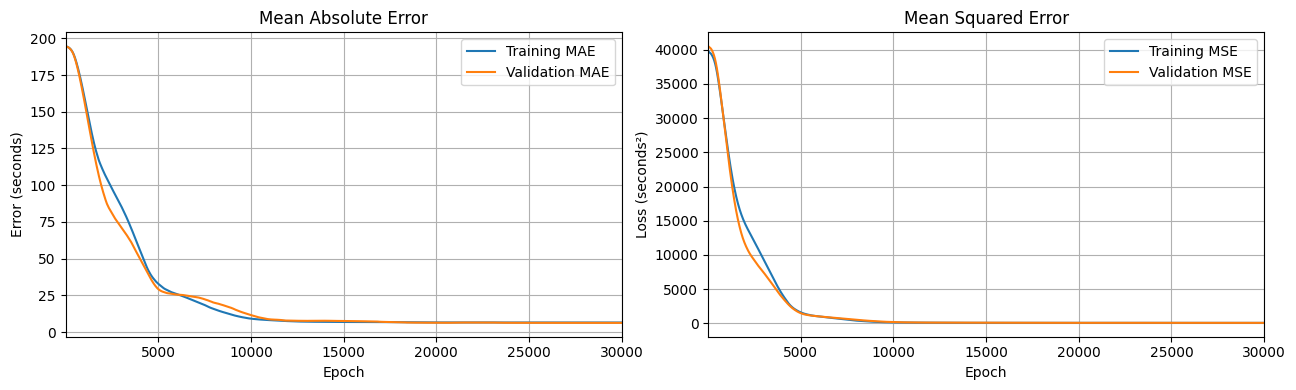

Epoch 30000/30000 | Train MAE: 6.48s | Val MAE: 6.24s

Training complete!


In [28]:

import time
from IPython.display import display, clear_output

# Training configuration
epochs = 30000
update_every = 400

# Store performance history
train_losses = []
val_losses = []
train_maes = []
val_maes = []

# Create live graphs
fig, (ax_mae, ax_mse) = plt.subplots(1, 2, figsize=(13, 4))

# Prevent duplicate plot output in Jupyter
plt.close(fig)

# MAE graph
train_mae_line, = ax_mae.plot([], [], label="Training MAE")
val_mae_line, = ax_mae.plot([], [], label="Validation MAE")

ax_mae.set_title("Mean Absolute Error")
ax_mae.set_xlabel("Epoch")
ax_mae.set_ylabel("Error (seconds)")
ax_mae.legend()
ax_mae.grid(True)

# MSE graph
train_mse_line, = ax_mse.plot([], [], label="Training MSE")
val_mse_line, = ax_mse.plot([], [], label="Validation MSE")

ax_mse.set_title("Mean Squared Error")
ax_mse.set_xlabel("Epoch")
ax_mse.set_ylabel("Loss (seconds²)")
ax_mse.legend()
ax_mse.grid(True)

fig.tight_layout()

# Training loop
for epoch in range(1, epochs + 1):

    # ----- TRAINING -----
    model.train()

    predictions = model(X_train_tensor)
    loss = criterion(predictions, y_train_tensor)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # ----- EVALUATION -----
    model.eval()

    with torch.no_grad():
        train_pred = model(X_train_tensor)
        val_pred = model(X_val_tensor)

        train_mse = criterion(train_pred, y_train_tensor).item()
        val_mse = criterion(val_pred, y_val_tensor).item()

        train_mae = torch.mean(
            torch.abs(train_pred - y_train_tensor)
        ).item()

        val_mae = torch.mean(
            torch.abs(val_pred - y_val_tensor)
        ).item()

    # Save performance history
    train_losses.append(train_mse)
    val_losses.append(val_mse)
    train_maes.append(train_mae)
    val_maes.append(val_mae)

    # ----- LIVE VISUALIZATION -----
    if epoch == 1 or epoch % update_every == 0:

        x = range(1, epoch + 1)

        # Update MAE curves
        train_mae_line.set_data(x, train_maes)
        val_mae_line.set_data(x, val_maes)

        # Update MSE curves
        train_mse_line.set_data(x, train_losses)
        val_mse_line.set_data(x, val_losses)

        # Automatically adjust axes
        for ax in (ax_mae, ax_mse):
            ax.relim()
            ax.autoscale_view()
            ax.set_xlim(1, max(50, epoch))

        # Refresh plots in notebook
        clear_output(wait=True)
        display(fig)

        print(
            f"Epoch {epoch}/{epochs} | "
            f"Train MAE: {train_mae:.2f}s | "
            f"Val MAE: {val_mae:.2f}s"
        )

        # Make updates visible
        time.sleep(0.2)

print("\nTraining complete!")



## 11. Compare Against Simple Baselines

Before improving our neural network, we should compare its predictions against simpler approaches.

We will evaluate three methods:

1. **Original baseline:** The existing `baseline_eta_s` calculation based on distance and speed.
2. **Corrected baseline:** The original baseline plus an average correction calculated using only training data.
3. **Neural network:** Our trained PyTorch model.

We will compare all three using validation Mean Absolute Error (MAE), measured in seconds.

A more complex neural network is only useful if it provides an advantage over simpler methods.

We will not use our test dataset for this comparison.


In [29]:

# Actual validation landing times
actual = y_val.to_numpy()

# Method 1: Original baseline
baseline_pred = val_df["baseline_eta_s"].to_numpy()

# Method 2: Corrected baseline
# Learn average correction from TRAINING data only
correction = (
    y_train - train_df["baseline_eta_s"]
).mean()

corrected_pred = baseline_pred + correction

# Method 3: Our neural network
model.eval()

with torch.no_grad():
    model_pred = model(X_val_tensor).squeeze(1).numpy()

# Calculate MAE for each method
def mae(predictions):
    return np.mean(np.abs(predictions - actual))

results = pd.DataFrame({
    "Method": [
        "Original baseline",
        "Corrected baseline",
        "Neural network"
    ],
    "Validation MAE (s)": [
        mae(baseline_pred),
        mae(corrected_pred),
        mae(model_pred)
    ]
})

print(f"Training-based correction: {correction:.2f} seconds")
display(results.sort_values("Validation MAE (s)"))


Training-based correction: 29.19 seconds


,Method,Validation MAE (s)
2,Neural network,6.235848
1,Corrected baseline,9.782904
0,Original baseline,31.880338



## 12. Analyze Individual Predictions

Our neural network has completed training, but average error alone does not tell us how well it performs on individual aircraft.

We will examine its predictions using our validation dataset.

### Predicted vs Actual Landing Time

We will create a scatter plot comparing predicted remaining time against actual remaining time.

A perfect prediction would fall exactly on the diagonal line where:

predicted time = actual time

The farther a point is from this line, the larger its prediction error.

### Prediction Error vs Distance

We will investigate whether prediction errors depend on the aircraft's distance from the runway threshold.

We define signed prediction error as:

error = predicted time - actual time

- **Positive error:** The model overestimates remaining landing time.
- **Negative error:** The model underestimates remaining landing time.
- **Zero error:** The prediction is perfect.

### Inspecting the Worst Predictions

We will display the 8 validation aircraft with the largest absolute prediction errors.

For each aircraft, we will examine:

- Actual remaining time
- Predicted remaining time
- Signed and absolute prediction errors
- Distance to runway threshold
- Groundspeed
- Altitude
- Original baseline ETA

This will help us identify possible weaknesses in the model.

Because our validation dataset contains only 29 aircraft, any patterns we observe should be treated cautiously.

We will not use the test dataset during this analysis.


Validation prediction analysis
-----------------------------------
MAE: 6.24 s
Maximum error: 21.84 s
Mean signed error: +0.47 s
Predictions within 10 seconds: 25/29


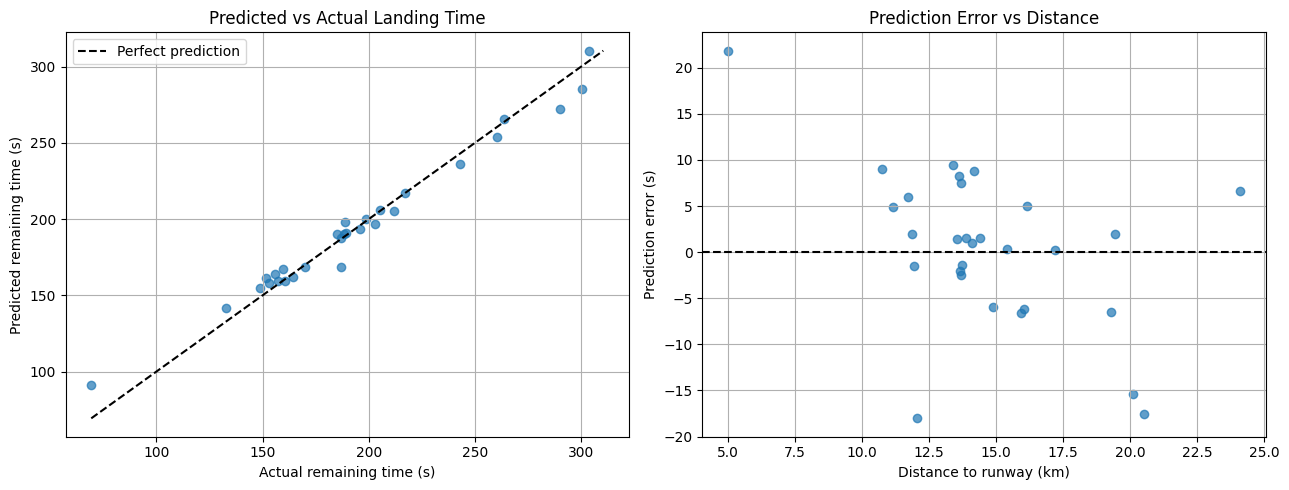


8 worst validation predictions:


,example_id,remaining_time_s,predicted_s,error_s,absolute_error_s,distance_to_threshold_m,groundspeed_mps,baro_altitude_m,baseline_eta_s
23,EHAM18R_485788_20230315T174218,69.39,91.230003,21.84,21.84,5013.05,70.99,243.84,70.64
26,EHAM18R_407688_20230315T193332,186.75,168.729996,-18.02,18.02,12072.72,84.37,571.50,143.23
28,EHAM18R_485876_20230315T210541,289.96,272.390015,-17.57,17.57,20517.06,86.94,998.22,236.28
27,EHAM18R_484c50_20230315T201124,300.38,284.959991,-15.43,15.43,20119.20,83.85,815.34,240.30
0,EHAM18R_485122_20230315T002114,151.70,161.100006,9.40,9.40,13377.16,110.09,739.14,121.52
6,EHAM18R_484cbc_20230315T085630,132.77,141.820007,9.05,9.05,10732.26,93.63,563.88,114.91
7,EHAM18R_484c50_20230315T091634,188.96,197.770004,8.82,8.82,14178.73,90.03,701.04,158.18
4,EHAM18R_4851f5_20230315T043353,155.77,164.000000,8.22,8.22,13607.75,102.89,693.42,132.26


In [30]:

# ----- GENERATE VALIDATION PREDICTIONS -----

model.eval()

with torch.no_grad():
    predictions = model(X_val_tensor).cpu().numpy().flatten()

# Create a DataFrame for analysis
val_results = val_df.reset_index(drop=True).copy()

val_results["predicted_s"] = predictions

# Calculate prediction errors
val_results["error_s"] = (
    val_results["predicted_s"] -
    val_results["remaining_time_s"]
)

val_results["absolute_error_s"] = (
    val_results["error_s"].abs()
)

# ----- DISPLAY ERROR STATISTICS -----

print("Validation prediction analysis")
print("-" * 35)

print(
    f"MAE: {val_results['absolute_error_s'].mean():.2f} s"
)

print(
    f"Maximum error: {val_results['absolute_error_s'].max():.2f} s"
)

print(
    f"Mean signed error: {val_results['error_s'].mean():+.2f} s"
)

print(
    f"Predictions within 10 seconds: "
    f"{(val_results['absolute_error_s'] <= 10).sum()}"
    f"/{len(val_results)}"
)

# ----- CREATE GRAPHS -----

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Graph 1: Predicted vs Actual
actual = val_results["remaining_time_s"]
predicted = val_results["predicted_s"]

axes[0].scatter(actual, predicted, alpha=0.7)

limits = [
    min(actual.min(), predicted.min()),
    max(actual.max(), predicted.max())
]

axes[0].plot(limits, limits, "k--", label="Perfect prediction")

axes[0].set_title("Predicted vs Actual Landing Time")
axes[0].set_xlabel("Actual remaining time (s)")
axes[0].set_ylabel("Predicted remaining time (s)")
axes[0].legend()
axes[0].grid(True)

# Graph 2: Error vs Distance
axes[1].scatter(
    val_results["distance_to_threshold_m"] / 1000,
    val_results["error_s"],
    alpha=0.7
)

axes[1].axhline(0, color="black", linestyle="--")

axes[1].set_title("Prediction Error vs Distance")
axes[1].set_xlabel("Distance to runway (km)")
axes[1].set_ylabel("Prediction error (s)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# ----- INSPECT WORST PREDICTIONS -----

print("\n8 worst validation predictions:")

columns_to_show = [
    "example_id",
    "remaining_time_s",
    "predicted_s",
    "error_s",
    "absolute_error_s",
    "distance_to_threshold_m",
    "groundspeed_mps",
    "baro_altitude_m",
    "baseline_eta_s"
]

worst_predictions = (
    val_results
    .sort_values("absolute_error_s", ascending=False)
    .head(8)
)

display(worst_predictions[columns_to_show].round(2))
